# F2.3 — Figuras de los pisos (adenda)

Figuras de apoyo de la tarea F2.3 (`results/f23_pisos/`, `docs/bitacora/F2.3.md`). **No cambian resultados ni decisiones.**

Reglas que sigue este notebook:

- **Toda cifra que aparece en las gráficas se lee de** `results/f23_pisos/*.csv`, `results/predictions/referencia/` y `results/canonical_numbers.json`. El notebook no recalcula ninguna cifra del reporte; cuando una cifra puede leerse de dos fuentes, se comprueba que coinciden.
- **Prohibido usar test.** Las predicciones se filtran a `split == 'val'`; las imágenes de test no se leen. `sin_test()` detiene el notebook si algún DataFrame usado en una figura contiene filas de test. Ninguna figura muestra test.
- **Única operación de modelo (figuras 4, 5 y 7):** la característica de brillo no se archivó. Se recalcula para `train` y `val` con la definición de la Enmienda 2 (intensidad media / 255 de la imagen nativa), verificando el SHA-256 de cada imagen contra `meta/data_manifest.csv`. Se reajusta el LogReg seleccionado solo con `train`, con los hiperparámetros de su manifiesto, y se exige que reproduzca **exactamente** el `p_dep` archivado en validación antes de dibujar.
- Colores por técnica de `src/viz/style.py` (siempre con etiqueta de texto); el resto en escala de grises.
- Exportación: PNG a 300 dpi en `results/f23_pisos/figures/`, con `style.save`.

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():          # nbconvert ejecuta desde notebooks/
    REPO = REPO.parent
sys.path[:0] = [str(REPO), str(REPO / 'src')]

from src import paths
from viz import style

style.apply()
RES = REPO / 'results' / 'f23_pisos'
PRED = REPO / 'results' / 'predictions' / 'referencia'
FIG = RES / 'figures'
TECHS = list(paths.TECHNIQUES)                      # perlin, gray_scott, lorenz
G_DARK, G_MID, G_LIGHT = style.INK, style.INK_SECONDARY, style.MUTED
A = style.FONT_SIZES['annot']


def sin_test(*dfs):
    # Detiene el notebook si algún DataFrame de una figura tiene filas de test
    for df in dfs:
        if 'split' in df.columns:
            assert not (df['split'] == 'test').any(), 'PROHIBIDO: filas de test en una figura'


def guardar(fig, nombre):
    p = style.save(fig, FIG / nombre)
    print(p.relative_to(REPO).as_posix())


def leer_val(nombre):
    df = pd.read_csv(PRED / nombre, float_precision='round_trip')
    df = df[df['split'] == 'val'].reset_index(drop=True)      # PROHIBIDO usar test
    sin_test(df)
    assert len(df) == 114
    return df

## Insumos

In [2]:
canon = json.loads((REPO / 'results' / 'canonical_numbers.json').read_text(encoding='utf-8'))['numbers']
rejilla = pd.read_csv(RES / 'rejilla_brillo.csv')
rejilla['combo'] = rejilla['combinacion'].map(json.loads)
rejilla['C'] = rejilla['combo'].map(lambda d: d['C'])
rejilla['cw'] = rejilla['combo'].map(lambda d: d['class_weight'] or 'None')
assert len(rejilla) == 78 and sorted(rejilla['tecnica'].unique()) == sorted(TECHS)

PISOS = ['majority', 'stratified'] + [f'brightness.{t}' for t in TECHS]
ARCHIVO = {'majority': 'none__majority__none__seed42.csv', 'stratified': 'none__stratified__none__seed42.csv',
           **{f'brightness.{t}': f'{t}__brightness__none__seed42.csv' for t in TECHS}}
ETIQ = {'majority': 'Mayoritaria', 'stratified': 'Aleatorio\nestratificado',
        **{f'brightness.{t}': f'Brillo\n{style.TECH_LABEL[t]}' for t in TECHS}}
F1 = {k: canon[f'ref.piso.{k}.f1_macro']['value']['val'] for k in PISOS}
CM = {k: canon[f'ref.piso.{k}.f1_macro']['confusion']['val'] for k in PISOS}
for k in PISOS:
    e = canon[f'ref.piso.{k}.f1_macro']
    assert e['value']['test'] is None and e['source']['path'].endswith(ARCHIVO[k])   # test bloqueado

pred = {k: leer_val(ARCHIVO[k]) for k in PISOS}
man = {k: json.loads((PRED / ARCHIVO[k].replace('.csv', '.manifest.json')).read_text(encoding='utf-8')) for k in PISOS}
SEL = {}
for t in TECHS:   # coherencia entre fuentes (sin recalcular)
    m = man[f'brightness.{t}']['model_selection']
    fila = rejilla[(rejilla['tecnica'] == t) & (rejilla['orden'] == m['orden_en_rejilla'])].iloc[0]
    assert fila['f1_val'] == m['f1_val'] == F1[f'brightness.{t}']
    assert fila['f1_val'] == rejilla.loc[rejilla['tecnica'] == t, 'f1_val'].max()
    SEL[t] = fila
for k in ('majority', 'stratified'):
    assert man[k]['model_selection']['f1_val'] == F1[k]

F1_TECHO = canon['ref.techo5d.f1_macro']['value']['val']
CONST_ESTR = json.loads((REPO / 'configs' / 'protocolo.json').read_text(encoding='utf-8'))['pisos_triviales']['stratified']['contrast_constant']
for k in PISOS:
    print(f'{k:<22} F1-Val = {F1[k]:.4f}   confusión val = {CM[k]}')
print(f'techo 5D val = {F1_TECHO:.4f}; constante del estratificado en los contrastes = {CONST_ESTR}')

majority               F1-Val = 0.3804   confusión val = {'fn': 44, 'fp': 0, 'tn': 70, 'tp': 0}
stratified             F1-Val = 0.5558   confusión val = {'fn': 24, 'fp': 24, 'tn': 46, 'tp': 20}
brightness.perlin      F1-Val = 0.6452   confusión val = {'fn': 13, 'fp': 27, 'tn': 43, 'tp': 31}
brightness.gray_scott  F1-Val = 0.4462   confusión val = {'fn': 38, 'fp': 12, 'tn': 58, 'tp': 6}
brightness.lorenz      F1-Val = 0.4519   confusión val = {'fn': 23, 'fp': 39, 'tn': 31, 'tp': 21}
techo 5D val = 0.7246; constante del estratificado en los contrastes = 0.5


## Figura 1 — F1-Val de los pisos (tabla de pisos, solo validación)

results/f23_pisos/figures/fig1_f1val_pisos.png


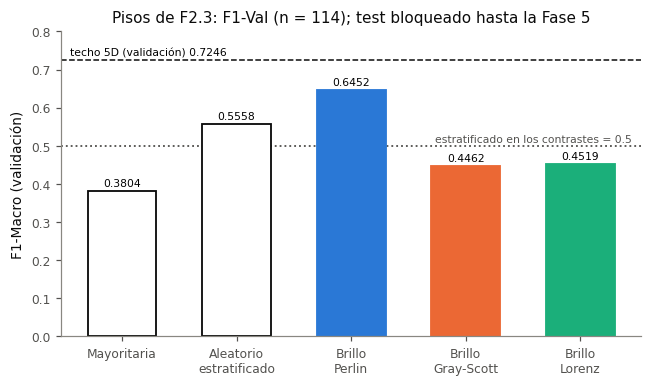

In [3]:
fig, ax = plt.subplots(figsize=(6.8, 3.6))
for i, k in enumerate(PISOS):
    t = k.split('.')[1] if k.startswith('brightness') else None
    col = style.TECH_COLOR[t] if t else G_DARK
    ax.bar(i, F1[k], width=0.6, color=col if t else 'white', edgecolor=col, lw=1.2, zorder=2)
    ax.text(i, F1[k] + 0.008, f'{F1[k]:.4f}', ha='center', va='bottom', fontsize=A)
ax.axhline(CONST_ESTR, color=G_MID, ls=':', lw=1.2, zorder=1)
ax.text(len(PISOS) - 0.55, CONST_ESTR + 0.005, f'estratificado en los contrastes = {CONST_ESTR}',
        ha='right', va='bottom', fontsize=A, color=G_MID)
ax.axhline(F1_TECHO, color=G_DARK, ls='--', lw=1, zorder=1)
ax.text(-0.45, F1_TECHO + 0.005, f'techo 5D (validación) {F1_TECHO:.4f}', ha='left', va='bottom', fontsize=A)
ax.set_xticks(range(len(PISOS)), [ETIQ[k] for k in PISOS])
ax.set_ylim(0, 0.8)
ax.set_ylabel('F1-Macro (validación)')
ax.set_title('Pisos de F2.3: F1-Val (n = 114); test bloqueado hasta la Fase 5')
guardar(fig, 'fig1_f1val_pisos')
plt.show()

## Figura 2 — Rejilla de LogReg del brillo: F1-Val frente a C, por técnica

results/f23_pisos/figures/fig2_rejilla_brillo.png


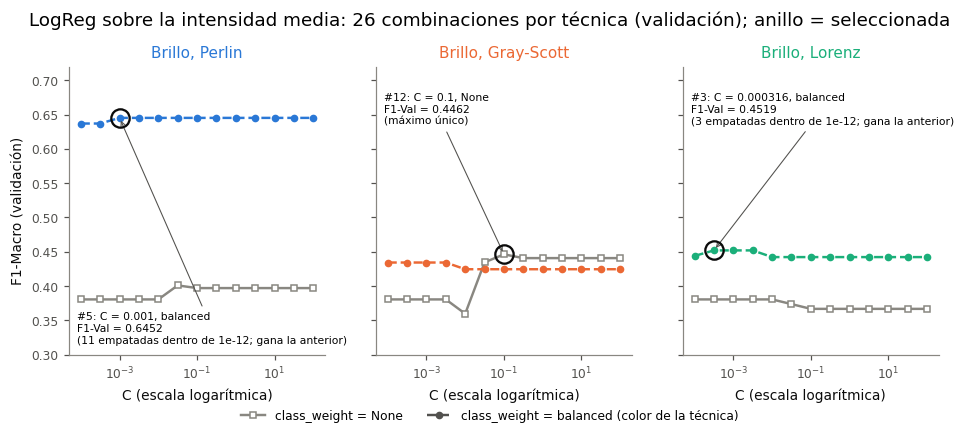

In [4]:
sin_test(rejilla)
fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.4), sharey=True)
for ax, t in zip(axes, TECHS):
    d = rejilla[rejilla['tecnica'] == t]
    col = style.TECH_COLOR[t]
    for cw, sty in (('None', dict(color=G_LIGHT, ls='-', marker='s', mfc='white')),
                    ('balanced', dict(color=col, ls='--', marker='o', mfc=col))):
        dd = d[d['cw'] == cw].sort_values('C')
        ax.plot(dd['C'], dd['f1_val'], label=f'class_weight = {cw}', ms=4, **sty)
    s = SEL[t]
    n_emp = int((d['f1_val'] >= d['f1_val'].max() - 1e-12).sum())
    ax.plot(s['C'], s['f1_val'], 'o', ms=12, mfc='none', mec=G_DARK, mew=1.5, zorder=4)
    nota = f'{n_emp} empatadas dentro de 1e-12; gana la anterior' if n_emp > 1 else 'máximo único'
    ax.annotate(f"#{int(s['orden'])}: C = {s['C']:.3g}, {s['cw']}\nF1-Val = {s['f1_val']:.4f}\n({nota})",
                (s['C'], s['f1_val']), xytext=(0.03, 0.04 if t == 'perlin' else 0.80),
                textcoords='axes fraction', fontsize=A, arrowprops=dict(arrowstyle='->', color=G_MID, lw=0.7))
    ax.set_xscale('log')
    ax.set_xlabel('C (escala logarítmica)')
    ax.set_title(f'Brillo, {style.TECH_LABEL[t]}', color=col)
axes[0].set_ylabel('F1-Macro (validación)')
axes[0].set_ylim(0.3, 0.72)
fig.legend(handles=[plt.Line2D([], [], color=G_LIGHT, ls='-', marker='s', mfc='white', ms=4, label='class_weight = None'),
                    plt.Line2D([], [], color=G_MID, ls='--', marker='o', ms=4, label='class_weight = balanced (color de la técnica)')],
           loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.1))
fig.suptitle('LogReg sobre la intensidad media: 26 combinaciones por técnica (validación); anillo = seleccionada', y=1.03)
guardar(fig, 'fig2_rejilla_brillo')
plt.show()

## Figura 3 — Matrices de confusión de los pisos en validación

results/f23_pisos/figures/fig3_confusion_pisos.png


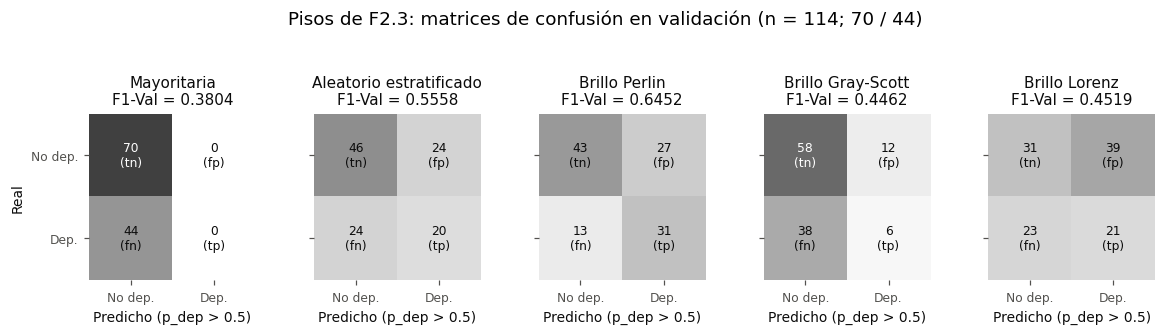

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(12.5, 2.9), gridspec_kw={'wspace': 0.35})
vmax = max(max(c.values()) for c in CM.values()) * 1.25
for ax, k in zip(axes, PISOS):
    c = CM[k]
    M = np.array([[c['tn'], c['fp']], [c['fn'], c['tp']]])
    ax.imshow(M, cmap='Greys', vmin=0, vmax=vmax)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f"{v}\n({[['tn', 'fp'], ['fn', 'tp']][i][j]})", ha='center', va='center', fontsize=8,
                color='white' if v > vmax * 0.55 else G_DARK)
    ax.set_xticks([0, 1], ['No dep.', 'Dep.'])
    ax.set_yticks([0, 1], ['No dep.', 'Dep.'] if k == PISOS[0] else ['', ''])
    ax.set_xlabel('Predicho (p_dep > 0.5)')
    ax.set_title(f"{ETIQ[k].replace(chr(10), ' ')}\nF1-Val = {F1[k]:.4f}")
    ax.spines[:].set_visible(False)
axes[0].set_ylabel('Real')
fig.suptitle('Pisos de F2.3: matrices de confusión en validación (n = 114; 70 / 44)', y=1.08)
guardar(fig, 'fig3_confusion_pisos')
plt.show()

## Brillo recalculado (train y val) y verificación contra lo archivado

Se recalcula la intensidad media / 255 de las imágenes de `train` y `val` (las de test no se leen), con verificación del SHA-256 de cada imagen contra `meta/data_manifest.csv`, y se reajusta el LogReg seleccionado de cada técnica solo con `train`. Se exige que el `p_dep` reajustado sea **idéntico** al archivado en validación.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

idx = pd.read_csv(paths.SAMPLE_INDEX, dtype={'sample_id': str, 'split': str})
idx = idx[idx['split'].isin(['train', 'val'])].sort_values(['split', 'sample_id']).reset_index(drop=True)
dm = pd.read_csv(paths.DATA_MANIFEST)
dm = dm[dm['kind'] == 'file'].set_index('rel_path')['sha256']

BRILLO, MODELO = {}, {}
for t in TECHS:
    rel_dir = paths.REL['IMAGES'][t]
    vals = []
    for name in idx[f'img_{t}']:
        f = paths.images_dir(t) / name
        assert hashlib.sha256(f.read_bytes()).hexdigest() == dm[f'{rel_dir}/{name}'], f'sha256 distinto: {name}'
        with Image.open(f) as im:
            assert im.mode == 'L' and im.size == (256, 256)
            vals.append(np.asarray(im, dtype=np.float64).mean() / 255.0)
    b = idx[['sample_id', 'split', 'y_true']].assign(brillo=vals)
    sin_test(b)
    tr, va = b[b['split'] == 'train'], b[b['split'] == 'val'].reset_index(drop=True)
    params = man[f'brightness.{t}']['config']['estimator_params']
    mod = make_pipeline(StandardScaler(), LogisticRegression(**params)).fit(tr[['brillo']].values, tr['y_true'].values)
    p = mod.predict_proba(va[['brillo']].values)[:, int(np.flatnonzero(mod.classes_ == 1)[0])]
    assert (va['sample_id'].values == pred[f'brightness.{t}']['sample_id'].values).all()
    assert np.array_equal(p, pred[f'brightness.{t}']['p_dep'].values), f'{t}: el reajuste no reproduce el p_dep archivado'
    BRILLO[t], MODELO[t] = b, mod
    print(f'{t:<11} {len(b)} imágenes (train + val) verificadas; p_dep reajustado = archivado ({params})')

perlin      1022 imágenes (train + val) verificadas; p_dep reajustado = archivado ({'penalty': 'l2', 'solver': 'lbfgs', 'max_iter': 5000, 'random_state': 42, 'C': 0.001, 'class_weight': 'balanced'})


gray_scott  1022 imágenes (train + val) verificadas; p_dep reajustado = archivado ({'penalty': 'l2', 'solver': 'lbfgs', 'max_iter': 5000, 'random_state': 42, 'C': 0.1, 'class_weight': None})


lorenz      1022 imágenes (train + val) verificadas; p_dep reajustado = archivado ({'penalty': 'l2', 'solver': 'lbfgs', 'max_iter': 5000, 'random_state': 42, 'C': 0.00031622776601683794, 'class_weight': 'balanced'})


## Figura 4 — Distribución del brillo por clase (train y val)

results/f23_pisos/figures/fig4_distribucion_brillo.png


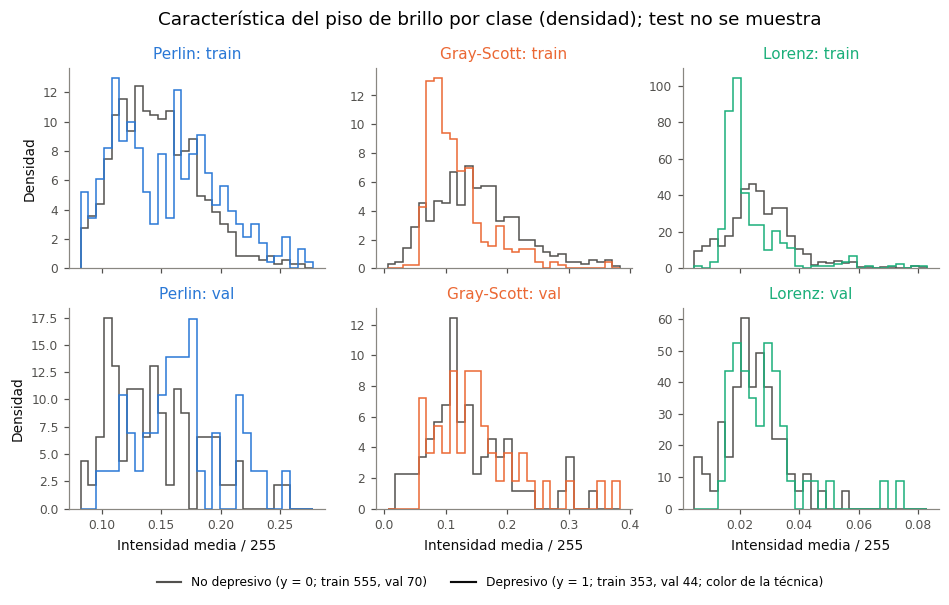

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(10.2, 5.2), sharex='col')
for j, t in enumerate(TECHS):
    b = BRILLO[t]
    bins = np.linspace(b['brillo'].min(), b['brillo'].max(), 31)
    for i, s in enumerate(['train', 'val']):
        ax = axes[i, j]
        for y, col in ((0, G_MID), (1, style.TECH_COLOR[t])):
            d = b[(b['split'] == s) & (b['y_true'] == y)]['brillo']
            ax.hist(d, bins=bins, histtype='step', lw=1.4, density=True, color=col)
        ax.set_title(f'{style.TECH_LABEL[t]}: {s}', color=style.TECH_COLOR[t])
        if j == 0:
            ax.set_ylabel('Densidad')
        if i == 1:
            ax.set_xlabel('Intensidad media / 255')
b0 = BRILLO[TECHS[0]]
n = {(s, y): int(((b0['split'] == s) & (b0['y_true'] == y)).sum()) for s in ('train', 'val') for y in (0, 1)}
fig.legend(handles=[plt.Line2D([], [], color=G_MID, lw=1.4, label=f"No depresivo (y = 0; train {n['train', 0]}, val {n['val', 0]})"),
                    plt.Line2D([], [], color=G_DARK, lw=1.4,
                               label=f"Depresivo (y = 1; train {n['train', 1]}, val {n['val', 1]}; color de la técnica)")],
           loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.05))
fig.suptitle('Característica del piso de brillo por clase (densidad); test no se muestra')
guardar(fig, 'fig4_distribucion_brillo')
plt.show()

## Figura 5 — `p_dep` del LogReg de brillo frente al brillo, en validación

results/f23_pisos/figures/fig5_pdep_brillo_val.png


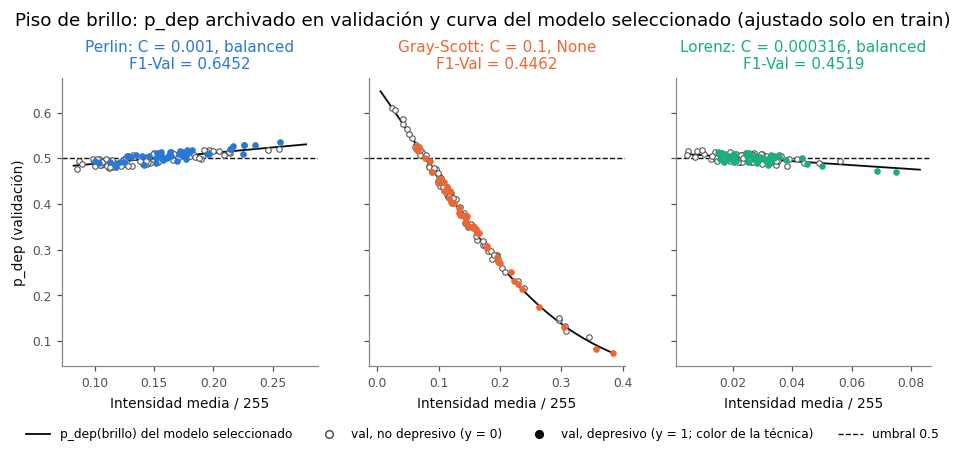

In [8]:
rng = np.random.default_rng(0)   # solo desplazamiento vertical para dibujar
fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.4), sharey=True)
for ax, t in zip(axes, TECHS):
    b = BRILLO[t]
    va = b[b['split'] == 'val'].reset_index(drop=True)
    sin_test(va)
    p = pred[f'brightness.{t}']['p_dep'].values          # archivado
    x = np.linspace(b['brillo'].min(), b['brillo'].max(), 400)
    ax.plot(x, MODELO[t].predict_proba(x[:, None])[:, 1], color=G_DARK, lw=1.2,
            label='p_dep(brillo) del modelo seleccionado')
    for y in (0, 1):
        m = va['y_true'].values == y
        ax.scatter(va['brillo'][m], p[m] + rng.uniform(-0.012, 0.012, m.sum()), s=13,
                   facecolor=style.TECH_COLOR[t] if y else 'white', edgecolor=style.TECH_COLOR[t] if y else G_MID,
                   lw=0.7, label=f"val, {'depresivo' if y else 'no depresivo'} (y = {y})", zorder=3)
    ax.axhline(0.5, color=G_DARK, ls='--', lw=0.9)
    s = SEL[t]
    ax.set_title(f"{style.TECH_LABEL[t]}: C = {s['C']:.3g}, {s['cw']}\nF1-Val = {s['f1_val']:.4f}",
                 color=style.TECH_COLOR[t])
    ax.set_xlabel('Intensidad media / 255')
axes[0].set_ylabel('p_dep (validación)')
fig.legend(handles=[plt.Line2D([], [], color=G_DARK, lw=1.2, label='p_dep(brillo) del modelo seleccionado'),
                    plt.Line2D([], [], marker='o', ls='', mfc='white', mec=G_MID, label='val, no depresivo (y = 0)'),
                    plt.Line2D([], [], marker='o', ls='', mfc=G_DARK, mec=G_DARK,
                               label='val, depresivo (y = 1; color de la técnica)'),
                    plt.Line2D([], [], color=G_DARK, ls='--', lw=0.9, label='umbral 0.5')],
           loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.12))
fig.suptitle('Piso de brillo: p_dep archivado en validación y curva del modelo seleccionado (ajustado solo en train)', y=1.06)
guardar(fig, 'fig5_pdep_brillo_val')
plt.show()

## Figura 6 — Aleatorio estratificado: predicciones archivadas en validación

results/f23_pisos/figures/fig6_estratificado_val.png


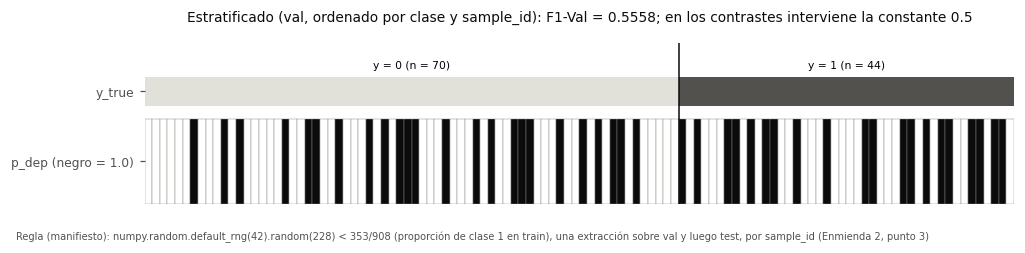

In [9]:
st = pred['stratified']
sin_test(st)
fig, ax = plt.subplots(figsize=(10.2, 1.9))
orden = st.sort_values(['y_true', 'sample_id']).reset_index(drop=True)
for i, r in orden.iterrows():
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, facecolor=G_DARK if r['p_dep'] == 1.0 else 'white', edgecolor=G_LIGHT, lw=0.3))
    ax.add_patch(plt.Rectangle((i, 1.15), 1, 0.35, facecolor=G_MID if r['y_true'] else style.GRID, lw=0))
n0 = int((orden['y_true'] == 0).sum())
ax.axvline(n0, color=G_DARK, lw=1)
ax.text(n0 / 2, 1.6, f'y = 0 (n = {n0})', ha='center', fontsize=A)
ax.text(n0 + (len(orden) - n0) / 2, 1.6, f'y = 1 (n = {len(orden) - n0})', ha='center', fontsize=A)
ax.set_xlim(0, len(orden)); ax.set_ylim(0, 1.9)
ax.set_yticks([0.5, 1.325], ['p_dep (negro = 1.0)', 'y_true']); ax.set_xticks([])
ax.spines[:].set_visible(False)
ax.set_title(f"Estratificado (val, ordenado por clase y sample_id): F1-Val = {F1['stratified']:.4f}; "
             f"en los contrastes interviene la constante {CONST_ESTR}", fontsize=9, pad=14)
fig.text(0.01, -0.06, f"Regla (manifiesto): {man['stratified']['config']['rule']}", fontsize=6.5, color=G_MID)
guardar(fig, 'fig6_estratificado_val')
plt.show()

## Figura 7 — (Ilustrativa) Imágenes de entrenamiento en distintos cuantiles de brillo

Solo `train`. Para cada técnica, la imagen más cercana a los cuantiles 5 %, 50 % y 95 % de la intensidad media; ilustra qué mide la característica del piso de brillo.

results/f23_pisos/figures/fig7_ejemplos_brillo_train.png


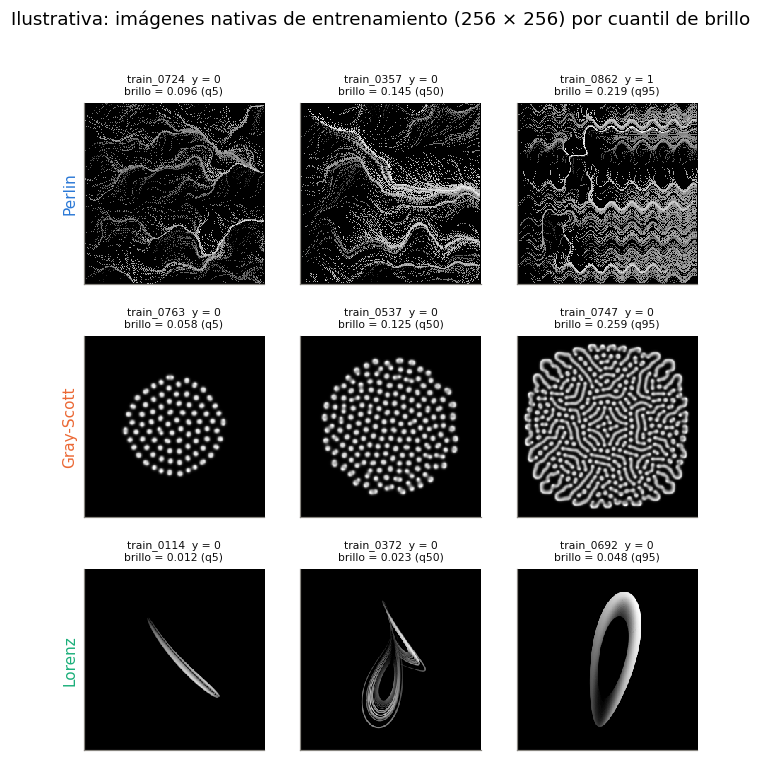

In [10]:
Q = [0.05, 0.5, 0.95]
img_de = idx.set_index('sample_id')
fig, axes = plt.subplots(3, 3, figsize=(7.2, 7.8))
for i, t in enumerate(TECHS):
    tr = BRILLO[t][BRILLO[t]['split'] == 'train'].reset_index(drop=True)
    sin_test(tr)
    for j, q in enumerate(Q):
        k = (tr['brillo'] - tr['brillo'].quantile(q)).abs().idxmin()
        with Image.open(paths.images_dir(t) / img_de.loc[tr.loc[k, 'sample_id'], f'img_{t}']) as im:
            style.gray(axes[i, j], np.asarray(im))
        axes[i, j].set_title(f"{tr.loc[k, 'sample_id']}  y = {int(tr.loc[k, 'y_true'])}\n"
                             f"brillo = {tr.loc[k, 'brillo']:.3f} (q{int(q * 100)})", fontsize=7)
    axes[i, 0].set_ylabel(style.TECH_LABEL[t], color=style.TECH_COLOR[t], fontsize=10)
fig.suptitle('Ilustrativa: imágenes nativas de entrenamiento (256 × 256) por cuantil de brillo')
guardar(fig, 'fig7_ejemplos_brillo_train')
plt.show()

## Archivos exportados

In [11]:
for p in sorted(FIG.glob('*.png')):
    with Image.open(p) as im:
        w, h = im.size
        dpi = im.info.get('dpi', (None,))[0]
    print(f'{p.relative_to(REPO).as_posix():<55} {w}×{h} px, dpi = {round(dpi) if dpi else None}')

results/f23_pisos/figures/fig1_f1val_pisos.png          1776×1049 px, dpi = 300
results/f23_pisos/figures/fig2_rejilla_brillo.png       2621×1195 px, dpi = 300
results/f23_pisos/figures/fig3_confusion_pisos.png      3177×911 px, dpi = 300
results/f23_pisos/figures/fig4_distribucion_brillo.png  2587×1650 px, dpi = 300
results/f23_pisos/figures/fig5_pdep_brillo_val.png      2620×1246 px, dpi = 300
results/f23_pisos/figures/fig6_estratificado_val.png    2797×688 px, dpi = 300
results/f23_pisos/figures/fig7_ejemplos_brillo_train.png 2073×2077 px, dpi = 300
